# LexiAssist — Phase 2 Evaluation Notebook

**Data Science course, final phase.** This notebook summarizes the *recorded* retrieval experiments and ten-answer pilot, with visible charts and transparent limitations. It is **not a model-training notebook**; pretrained embeddings and Llama 3 are used without fine-tuning. All grades are provisional **model-based** assessments, not independently human or legal-expert reviewed.

## Inputs and methodology

- Open Australian Legal Corpus: 1,000 sampled documents, 38,223 indexed chunks; target chunk length 250 words, 2-sentence overlap.
- A 40-question **development** subset selected RRF hyperparameters and expansion condition. A separate 60-question subset was held out for evaluation.
- Top-five retrieval metrics: Hit@5, P@5, MRR@5, candidate-pool nDCG@5 and mean local retrieval latency.
- The **503** pooled development pairs, and **439** held-out pooled test pairs, were graded provisionally; pooled nDCG is not exhaustive corpus-wide recall.
- The selected experimental pretrained configuration does **not** mean that the local website automatically uses expansion.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd() if (Path.cwd() / "phase2").is_dir() else Path.cwd().parent
DEV = pd.read_csv(ROOT / "phase2/evaluation/results/option_b_dev_combined_40/comparison_metrics.csv")
TEST = pd.read_csv(ROOT / "phase2/evaluation/results/option_b_test_final/comparison_metrics.csv")
ANSWERS = pd.read_csv(ROOT / "phase2/evaluation/results/answer_faithfulness/answers_scored_provisional.csv", encoding="utf-8-sig")
print(f"Development configurations: {len(DEV)}; test configurations: {len(TEST)}; graded answers: {len(ANSWERS)}")

Development configurations: 19; test configurations: 2; graded answers: 10


## Development: select parameters using development questions only

The table shows selected approaches from the **19** evaluated development configurations. The tuned pretrained variant achieves the highest pooled development nDCG@5; it is slower than standalone MiniLM. Configurations were selected **before** assessing the held-out test.

In [2]:
chosen = ["tfidf", "minilm", "pretrained_full", "pretrained_rrf30_expand0", "pretrained_rrf30_expand1", "pretrained_rrf60_expand1"]
cols = ["method", "questions", "hit_at_5", "precision_at_5", "ndcg_at_5", "mean_latency_ms"]
display(DEV.set_index("method").loc[chosen].reset_index()[cols])

,method,questions,hit_at_5,precision_at_5,ndcg_at_5,mean_latency_ms
0,tfidf,40,0.850,0.560,0.5996,391.3890
1,minilm,40,0.925,0.490,0.6013,50.2325
2,pretrained_full,40,0.925,0.585,0.6790,1233.0242
3,pretrained_rrf30_expand0,40,0.925,0.585,0.6790,1149.5420
4,pretrained_rrf30_expand1,40,0.925,0.620,0.7099,1465.7963
5,pretrained_rrf60_expand1,40,0.925,0.615,0.7078,1472.4845


## Held-out final test: two **locked** configurations

The two retrieval variants were fixed from development-set metrics. **Do not reselect parameters** using the test-set values. Both methods were evaluated on the same held-out questions and same judged pool.

,method,questions,hit_at_5,precision_at_5,mrr_at_5,ndcg_at_5,mean_latency_ms
0,selected_lightweight,60,0.9333,0.4333,0.7050,0.6564,390.1363
1,selected_pretrained,60,0.9500,0.4933,0.7908,0.7502,1597.9037


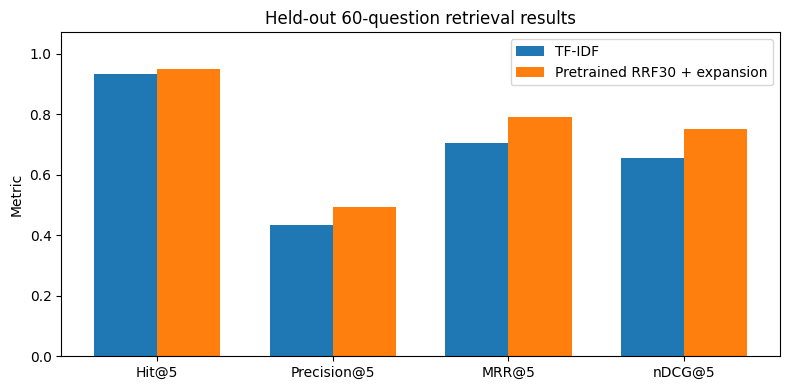

In [3]:
cols = ["method", "questions", "hit_at_5", "precision_at_5", "mrr_at_5", "ndcg_at_5", "mean_latency_ms"]
display(TEST[cols])
metrics=["hit_at_5", "precision_at_5", "mrr_at_5", "ndcg_at_5"]
labels=["Hit@5", "Precision@5", "MRR@5", "nDCG@5"]
xs=list(range(len(metrics)))
fig,ax=plt.subplots(figsize=(8,4))
ax.bar([i-0.18 for i in xs],[float(TEST.iloc[0][m]) for m in metrics],width=.36,label="TF-IDF")
ax.bar([i+0.18 for i in xs],[float(TEST.iloc[1][m]) for m in metrics],width=.36,label="Pretrained RRF30 + expansion")
ax.set_xticks(xs,labels);ax.set_ylim(0,1.07);ax.set_ylabel("Metric");ax.set_title("Held-out 60-question retrieval results");ax.legend();plt.tight_layout();plt.show()

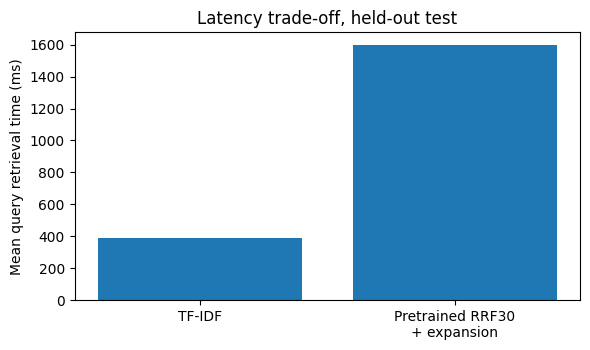

In [4]:
fig,ax=plt.subplots(figsize=(6,3.6))
ax.bar(["TF-IDF", "Pretrained RRF30\n+ expansion"],TEST["mean_latency_ms"])
ax.set_ylabel("Mean query retrieval time (ms)");ax.set_title("Latency trade-off, held-out test");plt.tight_layout();plt.show()

## Llama 3 output screening (10 questions)

The scores here describe whether the **generated text is supported by the five source excerpts** and correctly cites them. They do not show that an answer is correct against current Australian law. Raters were **model-based**, so the pilot should not be described as independent human evaluation.

,criterion,mean,max,full_score_answers
0,Answer relevance,1.2,2,3
1,Factual support,0.9,2,1
2,Citation support,0.7,2,1
3,Jurisdiction,0.7,1,7


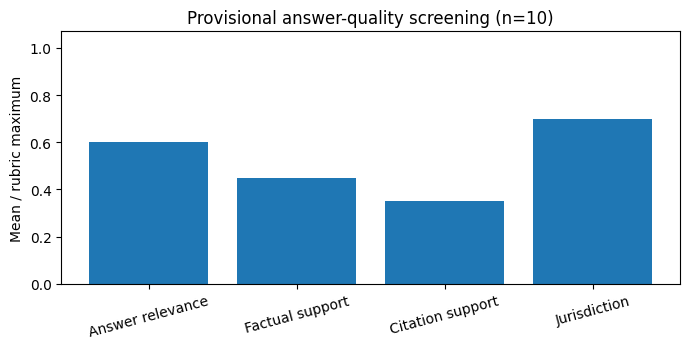

In [5]:
score_cols = {"Answer relevance": ("answer_relevance_0_1_2",2), "Factual support":("factual_support_0_1_2",2), "Citation support":("citation_support_0_1_2",2), "Jurisdiction":("jurisdiction_correct_0_1",1)}
means = {name: (ANSWERS[col].astype(int).mean(), maximum) for name,(col,maximum) in score_cols.items()}
summary = pd.DataFrame([{"criterion":name,"mean":round(avg,2),"max":maximum,"full_score_answers":int((ANSWERS[score_cols[name][0]].astype(int)==maximum).sum())} for name,(avg,maximum) in means.items()])
display(summary)
fig,ax=plt.subplots(figsize=(7,3.6))
ax.bar(summary["criterion"],summary["mean"]/summary["max"])
ax.set_ylim(0,1.07);ax.set_ylabel("Mean / rubric maximum");ax.set_title("Provisional answer-quality screening (n=10)");ax.tick_params(axis="x",rotation=15);plt.tight_layout();plt.show()

## Interpretation and limitations

**Selected pretrained RRF 30 + expansion** has higher held-out nDCG@5 (0.7502 vs 0.6564) and Precision@5 (0.4933 vs 0.4333), but average retrieval time is about 4.1 times longer (1,597.9 ms vs 390.1 ms). The model-based answer review identifies citation and faithfulness issues, so higher retrieval quality does not imply a legally safe generated answer. The corpus covers only 1,000 sampled records; query/source answerability and relevance judgments were not independently adjudicated; timings are unreplicated; labels may reflect bias and error. This project supplies educational retrieval evidence, not legal advice.

See the reproducible scripts under `phase2/evaluation/` and `phase2/evaluation/option_b/` for the experimental procedures.